# 2 - Evaluating implementation

In [367]:
# Importing all necessary packages and classes

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from decision_tree import DecisionTree
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier

# Setting set seed for reproducibility
SEED = 123

In [368]:
# Loading in data, and extracting feature variables and target labels

data = np.genfromtxt("churn-data.csv", delimiter=",", dtype=float, names=True)

feature_names = list(data.dtype.names[:-1])
target_name = data.dtype.names[-1]

X = np.array([data[feature] for feature in feature_names]).T
y = data[target_name].astype(int)

print(f"Feature columns names: {feature_names}")
print(f"Target label name: {target_name}")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

Feature columns names: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']
Target label name: Churn
X shape: (7032, 19)
y shape: (7032,)


In [369]:
# Calculating class proportions to find out which accuracy measure is best suited 
class_proportions = pd.Series(y).value_counts(normalize=True)

print(f"Class proportion: \n{class_proportions}")

Class proportion: 
0    0.734215
1    0.265785
Name: proportion, dtype: float64


## 2.1 - Model Selection

In [370]:
# Dividing into training- and validation-dataset and test-dataset
# Stratify is used to preserve class proportions

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, train_size = 0.85, random_state=SEED, stratify=y)

# Printing size and proportion of datasets
print(f"Training and validation set samples:\n{len(X_trainval)}\n")
print(f"Testing set samples:\n{len(X_test)}\n")

print(f"Training and validation set proportions:\n{pd.Series(y_trainval).value_counts(normalize=True)}\n")
print(f"Testing proportion:\n{pd.Series(y_test).value_counts(normalize=True)}")

Training and validation set samples:
5977

Testing set samples:
1055

Training and validation set proportions:
0    0.734148
1    0.265852
Name: proportion, dtype: float64

Testing proportion:
0    0.734597
1    0.265403
Name: proportion, dtype: float64


### Necessary functions

In [371]:
# Creating a function to create and fit decision trees

def train_decision_tree(X_train, y_train, DecisionTree, criterion, max_depth):
    
    # Creating a new decision tree from the given parameters

    # Check for preexisting classifier to set seed for reproducibility
    if (DecisionTree == DecisionTreeClassifier):
          decision_tree = DecisionTree(
                criterion=criterion, max_depth=max_depth, random_state=SEED)
    else:
        decision_tree = DecisionTree(criterion=criterion, max_depth=max_depth)

    # Fitting the decision tree on the training data
    decision_tree.fit(X_train, y_train)

    return decision_tree


In [372]:
# Creating a function for calculating accuracy-score and F1-score

def calculate_accuracies(y_true, y_pred):

    accuracies = {
        # Calculate accuracy score for predicted vs. true values
        "acc_score": accuracy_score(y_true, y_pred),

        # Calculate F1-score for predicted vs. true values
        # zero_division is needed to account for not churning being 0
        "f1_score": f1_score(y_true, y_pred, zero_division=0)
    }
    
    return accuracies

### Model selection

In [373]:
# Dividing into training- and validation-data using train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, train_size=0.8235, random_state=SEED, stratify=y_trainval)
    
# Printing number of samples in each dataset
N_train = len(X_train)
N_val = len(X_val)
N_test = len(X_test)

print(f"Number of samples in each split:\nTraining:\t{N_train}\nValidation:\t{N_val}\nTesting:\t{N_test}")

Number of samples in each split:
Training:	4922
Validation:	1055
Testing:	1055


In [374]:
# Creating a function to get the accuracy results on validation data with given criteria and depth

def get_hold_out_results(DecisionTree, X_train, y_train, X_val, y_val, impurity_criteria, max_depths):

    acc_results = []
    
    for criterion in impurity_criteria:
        for depth in max_depths:

            # Training decision tree
            decision_tree = train_decision_tree(X_train, y_train, DecisionTree, criterion, depth)

            # Calculating accuracy on training data 
            train_pred = decision_tree.predict(X_train)
            train_acc = calculate_accuracies(y_train, train_pred)
                
            # Calculating accuracy on validation data
            val_pred = decision_tree.predict(X_val)
            val_acc = calculate_accuracies(y_val, val_pred)

            acc_results.append({
                "criterion": criterion,
                "max_depth": depth,

                "train_acc_score": train_acc["acc_score"],
                "train_f1_score": train_acc["f1_score"],

                "val_acc_score": val_acc["acc_score"],
                "val_f1_score": val_acc["f1_score"],
            })

    # Creating a dataframe for results for easier handling and viewing
    acc_results_df = pd.DataFrame(acc_results)
    
    return acc_results_df

In [375]:
# Testing different hyperparameters and printing results

impurity_criteria = ["entropy", "gini"]
max_depths = [1, 2, 3, 4, 5, 7, 10, 15, 20, 30, None]

hold_out_acc_results_df = get_hold_out_results(
    DecisionTree, X_train, y_train, X_val, y_val, impurity_criteria, max_depths)

print(hold_out_acc_results_df)

   criterion  max_depth  train_acc_score  train_f1_score  val_acc_score  val_f1_score
0    entropy        1.0         0.734051        0.000000       0.734597      0.000000
1    entropy        2.0         0.740553        0.597795       0.755450      0.604294
2    entropy        3.0         0.778748        0.444104       0.790521      0.446115
3    entropy        4.0         0.778952        0.617171       0.792417      0.623064
4    entropy        5.0         0.799878        0.576344       0.810427      0.581590
5    entropy        7.0         0.818773        0.598560       0.800000      0.542299
6    entropy       10.0         0.862657        0.724531       0.780095      0.562264
7    entropy       15.0         0.953271        0.909733       0.759242      0.529630
8    entropy       20.0         0.990857        0.982699       0.746919      0.513661
9    entropy       30.0         0.998375        0.996935       0.752607      0.529730
10   entropy        NaN         0.998375        0.9969

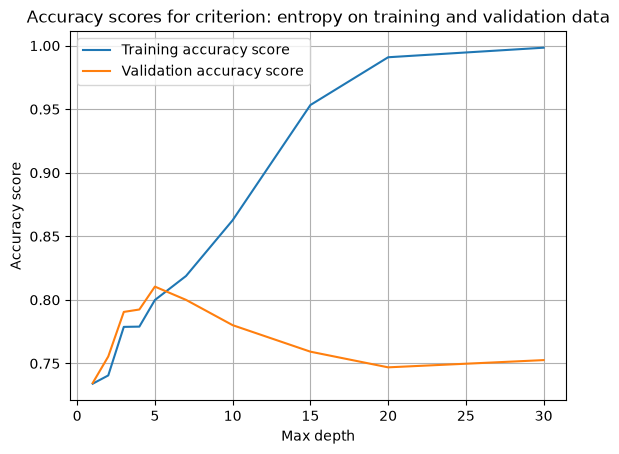

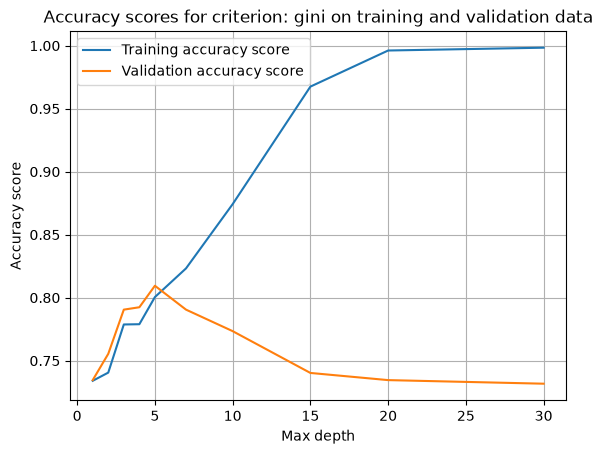

In [376]:
# Plotting the results of the accuracy scores on hold-out validation

for criterion in impurity_criteria:
    subset = hold_out_acc_results_df[hold_out_acc_results_df["criterion"] == criterion]
    
    plt.figure()
    plt.plot(subset["max_depth"],
             subset["train_acc_score"],
             label="Training accuracy score")

    plt.plot(subset["max_depth"],
             subset["val_acc_score"],
             label="Validation accuracy score")

    plt.xlabel("Max depth")
    plt.ylabel("Accuracy score")
    plt.title(f"Accuracy scores for criterion: {criterion} on training and validation data")

    plt.legend()
    plt.grid()
    plt.show()

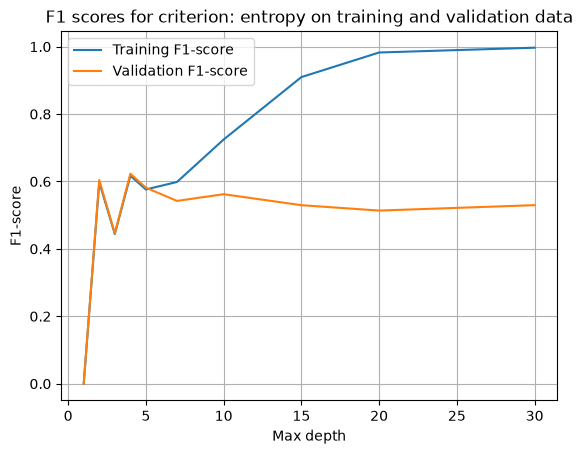

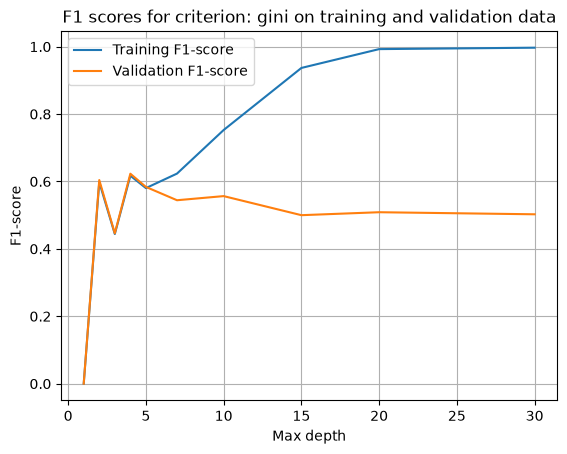

In [377]:
# Plotting the results of the F1-scores on hold-out validation

for criterion in impurity_criteria:
    subset = hold_out_acc_results_df[hold_out_acc_results_df["criterion"] == criterion]
    
    plt.figure()
    plt.plot(subset["max_depth"],
             subset["train_f1_score"],
             label="Training F1-score")

    plt.plot(subset["max_depth"],
             subset["val_f1_score"],
             label="Validation F1-score")

    plt.xlabel("Max depth")
    plt.ylabel("F1-score")
    plt.title(f"F1 scores for criterion: {criterion} on training and validation data")

    plt.legend()
    plt.grid()
    plt.show()

### K-fold cross-validation

In [378]:
# Creating a function for getting accuracy results with k-fold cross validation

def get_k_fold_results(DecisionTree, X, y, n_folds, seed, impurity_criteria, max_depths):

    # Stratified k-fold is used to again preserve class proportions
    k_fold = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    k_fold_acc_results = []

    for criterion in impurity_criteria:
        for depth in max_depths:
            k_fold_acc = []

            # Creating subsets of training and validation data to train and get accuracy and F1-scores on
            for fold, (train_idx, val_idx) in enumerate(
                k_fold.split(X, y), start=1):

                X_train_fold = X[train_idx]
                y_train_fold = y[train_idx]

                X_val_fold = X[val_idx]
                y_val_fold = y[val_idx]

                decision_tree = train_decision_tree(
                    X_train_fold, y_train_fold, DecisionTree, criterion, depth)
                
                pred = decision_tree.predict(X_val_fold)
                acc = calculate_accuracies(y_val_fold, pred)
                k_fold_acc.append(acc)

            acc_scores = [m["acc_score"] for m in k_fold_acc]
            f1_scores = [m["f1_score"] for m in k_fold_acc]

            k_fold_acc_results.append({
                "criterion": criterion,
                "max_depth": depth,

                "mean_acc_score": np.mean(acc_scores),
                "std_acc_score": np.std(acc_scores),

                "mean_f1_score": np.mean(f1_scores),
                "std_f1_score": np.std(f1_scores)        
            })

    k_fold_acc_results_df = pd.DataFrame(k_fold_acc_results)

    return k_fold_acc_results_df

In [379]:
# Printing results of stratified k-fold cross-validation with given folds

N_folds = 5

k_fold_acc_results_df = get_k_fold_results(
    DecisionTree, X_trainval, y_trainval, N_folds, SEED, impurity_criteria, max_depths)

print(k_fold_acc_results_df)

   criterion  max_depth  mean_acc_score  std_acc_score  mean_f1_score  std_f1_score
0    entropy        1.0        0.734148       0.000307       0.000000      0.000000
1    entropy        2.0        0.743180       0.008871       0.598648      0.017466
2    entropy        3.0        0.780491       0.008459       0.472017      0.017409
3    entropy        4.0        0.779821       0.008755       0.485248      0.082235
4    entropy        5.0        0.785512       0.009831       0.602823      0.025210
5    entropy        7.0        0.782665       0.008125       0.551518      0.009818
6    entropy       10.0        0.765435       0.010087       0.543026      0.023546
7    entropy       15.0        0.738998       0.006425       0.514587      0.011908
8    entropy       20.0        0.734315       0.008768       0.505908      0.011495
9    entropy       30.0        0.732140       0.006774       0.503414      0.006671
10   entropy        NaN        0.732140       0.006774       0.503414      0

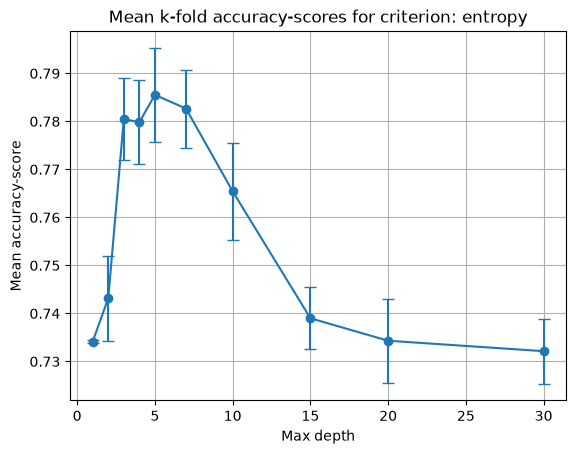

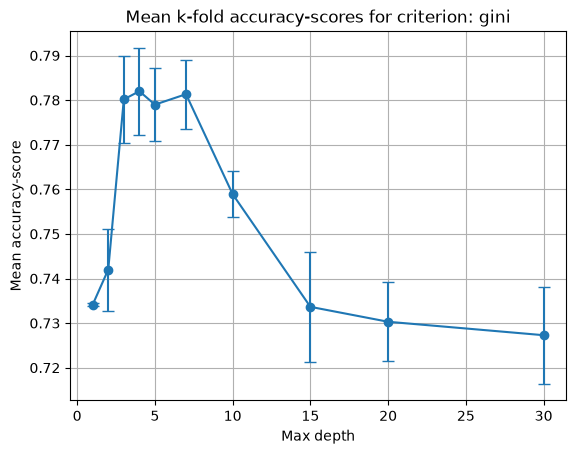

In [380]:
# Plotting the results of the mean accuracy scores of the k-fold on validation data

for criterion in impurity_criteria:
    subset = k_fold_acc_results_df[k_fold_acc_results_df["criterion"] == criterion]
    
    plt.figure()
    plt.errorbar(subset["max_depth"],
             subset["mean_acc_score"],
             yerr=subset["std_acc_score"],
             marker="o", capsize=4)

    plt.xlabel("Max depth")
    plt.ylabel("Mean accuracy-score")
    plt.title(f"Mean k-fold accuracy-scores for criterion: {criterion}")

    plt.grid()
    plt.show()

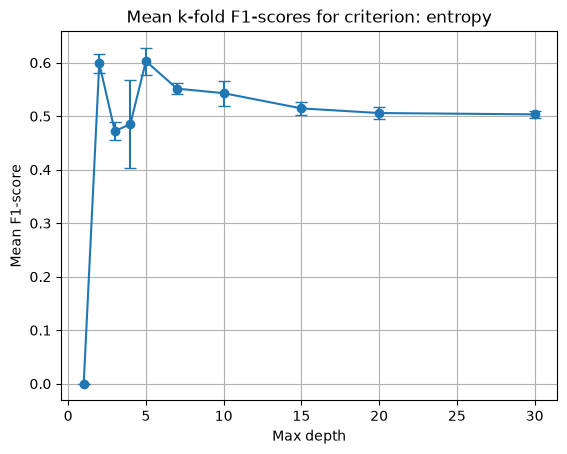

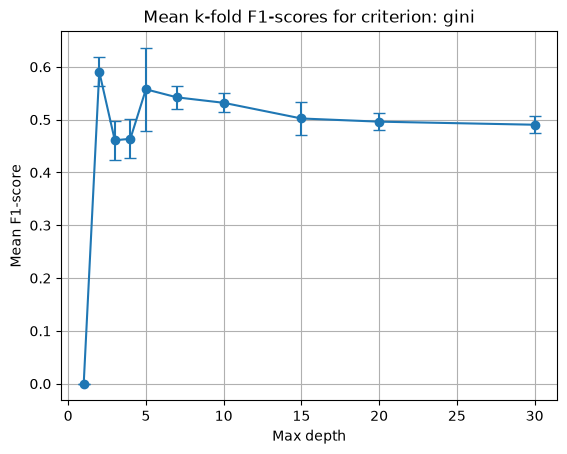

In [381]:
# Plotting the results of the mean F1-scores of the k-fold on validation data

for criterion in impurity_criteria:
    subset = k_fold_acc_results_df[k_fold_acc_results_df["criterion"] == criterion]
    
    plt.figure()
    plt.errorbar(subset["max_depth"],
             subset["mean_f1_score"],
             yerr=subset["std_f1_score"],
             marker="o", capsize=4)

    plt.xlabel("Max depth")
    plt.ylabel("Mean F1-score")
    plt.title(f"Mean k-fold F1-scores for criterion: {criterion}")

    plt.grid()
    plt.show()

In [382]:
# Selecting best model based on F1-score on validation data from hold-out validation
hold_out_idx = hold_out_acc_results_df["val_f1_score"].idxmax()
best_model = hold_out_acc_results_df.loc[hold_out_idx]

# Selecting best model based on mean F1-score on validation data from k-fold cross-validation
k_fold_idx = k_fold_acc_results_df["mean_f1_score"].idxmax()
best_k_fold_model = k_fold_acc_results_df.loc[k_fold_idx]

# Printing both strategies' output
print(f"Best model using hold-out validation:\n\n{best_model}")
print("\n------------------------------------------")
print(f"Best model using k-fold cross validation:\n\n{best_k_fold_model}")

Best model using hold-out validation:

criterion           entropy
max_depth               4.0
train_acc_score    0.778952
train_f1_score     0.617171
val_acc_score      0.792417
val_f1_score       0.623064
Name: 3, dtype: object

------------------------------------------
Best model using k-fold cross validation:

criterion          entropy
max_depth              5.0
mean_acc_score    0.785512
std_acc_score     0.009831
mean_f1_score     0.602823
std_f1_score       0.02521
Name: 4, dtype: object


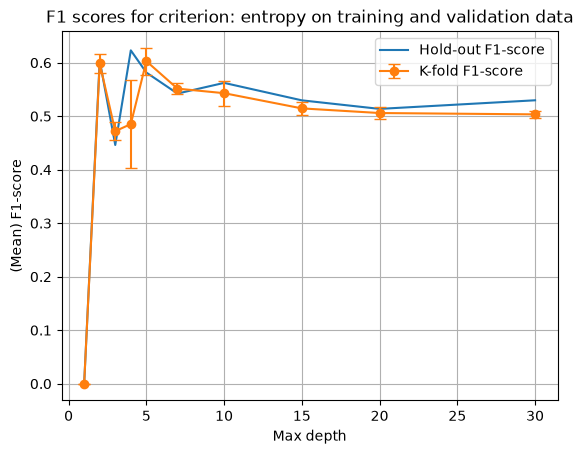

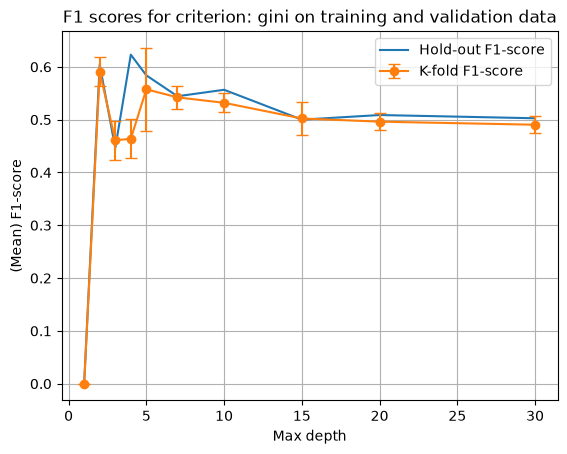

In [383]:
# Plotting the results of the F1-scores of both methods

for criterion in impurity_criteria:
    subset_hold_out = hold_out_acc_results_df[hold_out_acc_results_df["criterion"] == criterion]

    plt.figure()
    plt.plot(subset_hold_out["max_depth"],
             subset_hold_out["val_f1_score"],
             label="Hold-out F1-score")

    subset_k_fold = k_fold_acc_results_df[k_fold_acc_results_df["criterion"] == criterion]
        
    plt.errorbar(subset_k_fold["max_depth"],
             subset_k_fold["mean_f1_score"],
             yerr=subset_k_fold["std_f1_score"],
             marker="o", capsize=4,
             label="K-fold F1-score")

    plt.xlabel("Max depth")
    plt.ylabel("(Mean) F1-score")
    plt.title(f"F1 scores for criterion: {criterion} on training and validation data")

    plt.legend()
    plt.grid()
    plt.show()

In [384]:
# If hold-out and k-fold do not agree on best parameters, print k-fold output for best hold out

if (best_model["criterion"] != best_k_fold_model["criterion"]
    or best_model["max_depth"] != best_k_fold_model["max_depth"]):

    selected_k_fold = k_fold_acc_results_df[
        (k_fold_acc_results_df["criterion"] == best_model["criterion"]) &
        (k_fold_acc_results_df["max_depth"] == best_model["max_depth"])].iloc[0]

    print(f"Best hold_out model:\n {best_model}")
    print("---------------------------")
    print(f"\nAccompanying k-fold cross-validation results: \n{selected_k_fold}")

Best hold_out model:
 criterion           entropy
max_depth               4.0
train_acc_score    0.778952
train_f1_score     0.617171
val_acc_score      0.792417
val_f1_score       0.623064
Name: 3, dtype: object
---------------------------

Accompanying k-fold cross-validation results: 
criterion          entropy
max_depth              4.0
mean_acc_score    0.779821
std_acc_score     0.008755
mean_f1_score     0.485248
std_f1_score      0.082235
Name: 3, dtype: object


## 2.2 - Model evaluation and Comparison to Preexisting Implementations

In [385]:
# Comparing the best model selection method to a dummy classifier using hold-out validation

best_acc_score = best_model["val_acc_score"]
best_f1_score = best_model["val_f1_score"]

dummy_classifier = DummyClassifier(strategy="stratified", random_state=SEED)
dummy_classifier.fit(X_train, y_train)
dummy_pred = dummy_classifier.predict(X_val)
dummy_acc = accuracy_score(y_val, dummy_pred)
dummy_f1 = f1_score(y_val, dummy_pred)

print(f"A dummy classifier with a stratify-strategy has an accuracy-score of {round(dummy_acc, 4)} \
      \n and an F1-score of {round(dummy_f1, 4)} compared to the best tuned model with an \
      \n accuracy-score of {round(best_acc_score, 4)} and an F1-score of {round(best_f1_score, 4)}")

A dummy classifier with a stratify-strategy has an accuracy-score of 0.5934       
 and an F1-score of 0.207 compared to the best tuned model with an       
 accuracy-score of 0.7924 and an F1-score of 0.6231


In [386]:
# Checking the performance against a preexisting decision tree implementation
# Using the same method of hyperparameter tuning and model selection to ensure fairness

preexisting_hold_out_results_df = get_hold_out_results(
    DecisionTreeClassifier, X_train, y_train, X_val, y_val, impurity_criteria, max_depths)

print(preexisting_hold_out_results_df)

   criterion  max_depth  train_acc_score  train_f1_score  val_acc_score  val_f1_score
0    entropy        1.0         0.734051        0.000000       0.734597      0.000000
1    entropy        2.0         0.740553        0.597795       0.755450      0.604294
2    entropy        3.0         0.778748        0.444104       0.790521      0.446115
3    entropy        4.0         0.778952        0.617171       0.792417      0.623064
4    entropy        5.0         0.799878        0.576344       0.810427      0.581590
5    entropy        7.0         0.818773        0.598560       0.799052      0.541126
6    entropy       10.0         0.862251        0.724614       0.776303      0.558052
7    entropy       15.0         0.952255        0.907807       0.765877      0.541744
8    entropy       20.0         0.990248        0.981524       0.761137      0.536765
9    entropy       30.0         0.998375        0.996935       0.763981      0.552962
10   entropy        NaN         0.998375        0.9969

In [387]:
# Using stratified k-fold cross-validation as a comparison to hold-out validation on preexisting classifier

preexisting_k_fold_results_df = get_k_fold_results(
    DecisionTreeClassifier, X_trainval, y_trainval, N_folds, SEED, impurity_criteria, max_depths)

print(preexisting_k_fold_results_df)

   criterion  max_depth  mean_acc_score  std_acc_score  mean_f1_score  std_f1_score
0    entropy        1.0        0.734148       0.000307       0.000000      0.000000
1    entropy        2.0        0.743180       0.008871       0.598648      0.017466
2    entropy        3.0        0.780491       0.008459       0.472017      0.017409
3    entropy        4.0        0.779821       0.008755       0.485248      0.082235
4    entropy        5.0        0.785512       0.009831       0.602823      0.025210
5    entropy        7.0        0.781661       0.008478       0.550094      0.009645
6    entropy       10.0        0.766773       0.011882       0.543602      0.025821
7    entropy       15.0        0.739835       0.003745       0.517467      0.008719
8    entropy       20.0        0.732642       0.013632       0.500565      0.015122
9    entropy       30.0        0.729128       0.009349       0.495003      0.006191
10   entropy        NaN        0.729965       0.008377       0.496054      0

In [388]:
# Checking best hold-out and k-fold validation models for preexisting classifier

hold_out_preexisting_idx = preexisting_hold_out_results_df["val_f1_score"].idxmax()
hold_out_preexisting = preexisting_hold_out_results_df.loc[hold_out_preexisting_idx]

k_fold_preexisting_idx = preexisting_k_fold_results_df["mean_f1_score"].idxmax()
k_fold_preexisting = preexisting_k_fold_results_df.loc[k_fold_preexisting_idx]

# Printing both strategies' output
print(f"Best preexisting model using hold-out validation:\n\n{hold_out_preexisting}")
print("\n------------------------------------------")
print(f"Best preexisting model using k-fold cross validation:\n\n{k_fold_preexisting}")

Best preexisting model using hold-out validation:

criterion           entropy
max_depth               4.0
train_acc_score    0.778952
train_f1_score     0.617171
val_acc_score      0.792417
val_f1_score       0.623064
Name: 3, dtype: object

------------------------------------------
Best preexisting model using k-fold cross validation:

criterion          entropy
max_depth              5.0
mean_acc_score    0.785512
std_acc_score     0.009831
mean_f1_score     0.602823
std_f1_score       0.02521
Name: 4, dtype: object


In [389]:
# If hold-out and k-fold do not agree on best parameters, print k-fold output for best hold out

if (hold_out_preexisting["criterion"] != k_fold_preexisting["criterion"]
    or hold_out_preexisting["max_depth"] != k_fold_preexisting["max_depth"]):

    selected_k_fold = preexisting_k_fold_results_df[
        (preexisting_k_fold_results_df["criterion"] == hold_out_preexisting["criterion"]) &
        (preexisting_k_fold_results_df["max_depth"] == hold_out_preexisting["max_depth"])].iloc[0]

    print(f"Best hold_out model:\n {hold_out_preexisting}")
    print("---------------------------")
    print(f"\nAccompanying k-fold cross-validation results: \n{selected_k_fold}")

Best hold_out model:
 criterion           entropy
max_depth               4.0
train_acc_score    0.778952
train_f1_score     0.617171
val_acc_score      0.792417
val_f1_score       0.623064
Name: 3, dtype: object
---------------------------

Accompanying k-fold cross-validation results: 
criterion          entropy
max_depth              4.0
mean_acc_score    0.779821
std_acc_score     0.008755
mean_f1_score     0.485248
std_f1_score      0.082235
Name: 3, dtype: object


In [390]:
# Comparing preexisting vs. self-made implementation, using F1 score on validation data

print(f"Best model using self-made implementation:\n\n{best_model}")
print("\n------------------------------------------")
print(f"Best model using preexisting implementation:\n\n{hold_out_preexisting}")
print("\n------------------------------------------")

best_f1_score_preexisting = hold_out_preexisting["val_f1_score"]
best_acc_score_preexisting = hold_out_preexisting["val_acc_score"]

if (best_f1_score < best_f1_score_preexisting):
    print(f"The preexisting implementation has the better F1-score on validation data with F1-score: {round(best_f1_score_preexisting,4)}")

elif (best_f1_score == best_f1_score_preexisting):
    print(f"Both implementations have the same F1-score on validation data with F1-score: {round(best_f1_score,4)}")
    
else:
    print(f"The self-made implementation has the better F1-score on validation data with F1-score: {round(best_f1_score,4)}")


Best model using self-made implementation:

criterion           entropy
max_depth               4.0
train_acc_score    0.778952
train_f1_score     0.617171
val_acc_score      0.792417
val_f1_score       0.623064
Name: 3, dtype: object

------------------------------------------
Best model using preexisting implementation:

criterion           entropy
max_depth               4.0
train_acc_score    0.778952
train_f1_score     0.617171
val_acc_score      0.792417
val_f1_score       0.623064
Name: 3, dtype: object

------------------------------------------
Both implementations have the same F1-score on validation data with F1-score: 0.6231


In [391]:
# Doing a final evaluation on the test dataset with self-made vs. preexisting implementation

final_model_self_made = DecisionTree(best_model["criterion"], best_model["max_depth"])
final_model_self_made.fit(X_train, y_train)
test_pred_self_made = final_model_self_made.predict(X_test)

final_model_preexisting = DecisionTreeClassifier(
    criterion=hold_out_preexisting["criterion"],
      max_depth=int(hold_out_preexisting["max_depth"]),
        random_state=SEED)
final_model_preexisting.fit(X_train, y_train)
test_pred_preexisting = final_model_preexisting.predict(X_test)

acc_results_test_self_made = calculate_accuracies(y_test, test_pred_self_made)
acc_results_test_preexisting = calculate_accuracies(y_test, test_pred_preexisting)

test_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy_score",
        "F1_score"
    ],
    "Self_made_decision_tree": [
        acc_results_test_self_made["acc_score"],
        acc_results_test_self_made["f1_score"]
    ],
    "Preexisting_decision_tree": [
        acc_results_test_preexisting["acc_score"],
        acc_results_test_preexisting["f1_score"]
    ]
})

print(test_comparison)

           Metric  Self_made_decision_tree  Preexisting_decision_tree
0  Accuracy_score                 0.764929                   0.764929
1        F1_score                 0.586667                   0.586667


Self made decision tree:
[[631 144]
 [104 176]]


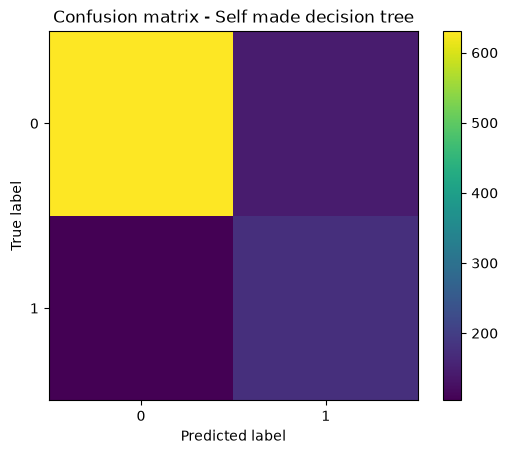

Preexisting decision tree:
[[631 144]
 [104 176]]


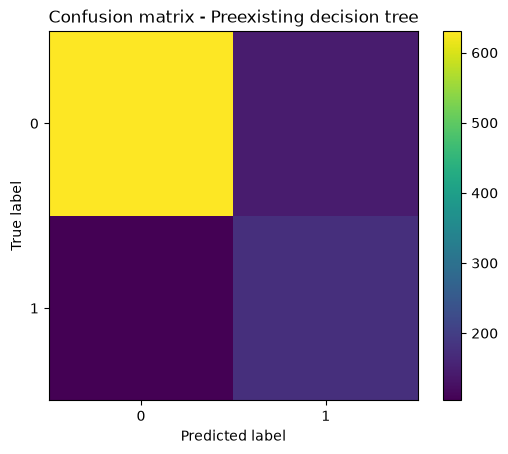

In [392]:
# Visualizing the results using confusion matrices

conf_matrix_self_made = confusion_matrix(y_test, test_pred_self_made)
conf_matrix_preexisting = confusion_matrix(y_test, test_pred_preexisting)

print(f"Self made decision tree:\n{conf_matrix_self_made}")

plt.figure()
plt.imshow(conf_matrix_self_made)
plt.title("Confusion matrix - Self made decision tree")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.colorbar()
plt.xticks([0,1])
plt.yticks([0,1])
plt.show()

print(f"Preexisting decision tree:\n{conf_matrix_preexisting}")
plt.figure()
plt.imshow(conf_matrix_preexisting)
plt.title("Confusion matrix - Preexisting decision tree")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.colorbar()
plt.xticks([0,1])
plt.yticks([0,1])
plt.show()

# 3 - Feature importance

In [393]:
# Implementing method for checking impact of permutations on accuracy of model

def permutation_importance(model, X, y, metric, n_repeats, seed):

    # Creating a random variable for permuting features
    rand = np.random.default_rng(seed)

    # Getting a baseline prediction and score for the model
    y_pred = model.predict(X)
    baseline_score = metric(y, y_pred)

    importance_scores = np.zeros(X.shape[1])

    # Going through and permuting all features, then getting prediction and scores for the model
    for feature_idx in range(X.shape[1]):
        permuted_scores = []

        for _ in range(n_repeats):
            X_permuted = X.copy()
            X_permuted[:, feature_idx] = rand.permutation(X_permuted[:, feature_idx])

            y_pred = model.predict(X_permuted)
            permuted_score = metric(y, y_pred)
            permuted_scores.append(permuted_score)

        importance_scores[feature_idx] = baseline_score - 1/n_repeats * np.sum(permuted_scores)

    return importance_scores

In [394]:
# Calculating permutation importance on test dataset with 30 repeats

n_repeats = 30
model = DecisionTree(best_model["criterion"], best_model["max_depth"])
model.fit(X_train, y_train)

importance_scores = permutation_importance(
    model, X_test, y_test, accuracy_score, n_repeats, SEED)

permutation_results = pd.DataFrame({
    "feature": feature_names,
    "importance_score": importance_scores
})

permutation_results = permutation_results.sort_values("importance_score", ascending=False)
print(permutation_results)

             feature  importance_score
8     OnlineSecurity      4.265403e-02
14          Contract      3.488152e-02
7    InternetService      1.642970e-02
4             tenure      9.889415e-03
2            Partner      3.330669e-16
0             gender      3.330669e-16
1      SeniorCitizen      3.330669e-16
6      MultipleLines      3.330669e-16
5       PhoneService      3.330669e-16
9       OnlineBackup      3.330669e-16
3         Dependents      3.330669e-16
10  DeviceProtection      3.330669e-16
11       TechSupport      3.330669e-16
12       StreamingTV      3.330669e-16
13   StreamingMovies      3.330669e-16
15  PaperlessBilling      3.330669e-16
16     PaymentMethod      3.330669e-16
17    MonthlyCharges      3.330669e-16
18      TotalCharges      3.330669e-16


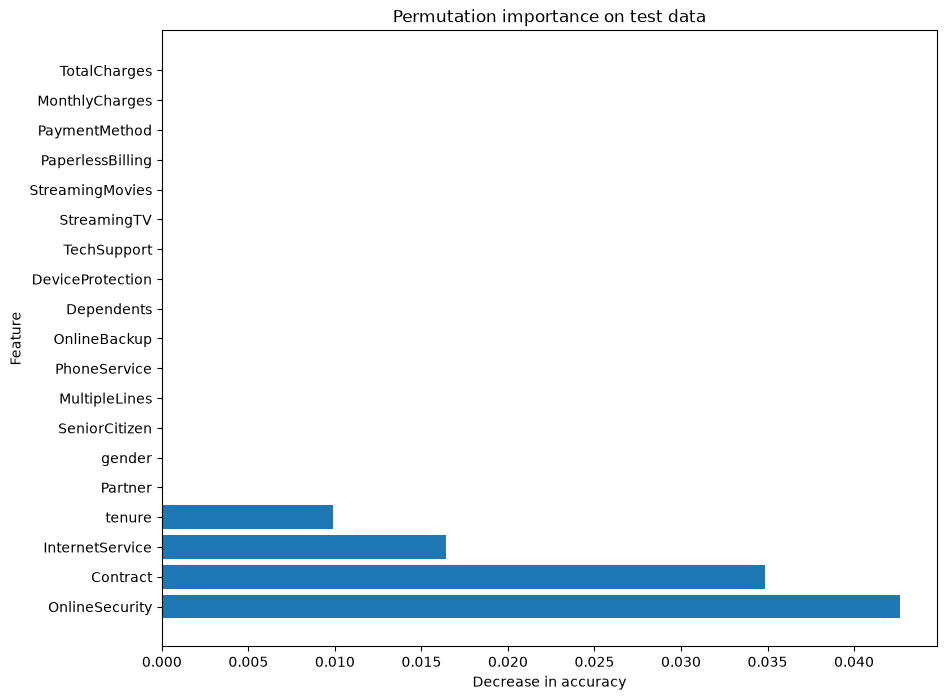

In [395]:
# Visualizing the permutation importance using barplot
plt.figure(figsize=(10,8))
plt.barh(permutation_results["feature"], permutation_results["importance_score"])
plt.title("Permutation importance on test data")
plt.xlabel("Decrease in accuracy")
plt.ylabel("Feature")
plt.show()